# Laboratorio Dry Bean - Sprint 1: comprensión y preparación

**Proyecto:** Clasificación de variedades de frijol seco (Dry Bean Dataset, UCI 602)
**Equipo:** Jacobo Unzueta y Rommel Prieto - Maestría en IA y Ciencia de Datos, Universidad Autónoma de Occidente
**Metodologías:** CRISP-DM · TDSP · Scrum ML
**Sprint 1:** PB-01 (carga del dataset) y PB-02 (calidad de datos) + preparación de datos

Este notebook es la **cara visible** del Sprint 1: la lógica reproducible vive en
`src/` y aquí se ejecuta, se explica y se revisa. Ejecutar desde la raíz del repositorio.

## Definition of Done del Sprint 1

- [x] El dataset se descarga desde UCI y queda versionado en `data/raw/`
- [x] Se reportan nulos y duplicados
- [x] Split train/test estratificado y reproducible
- [x] Pipeline de preprocesamiento listo para el Sprint 2
- [x] Reporte y figuras en `outputs/reports/sprint1/`


## 0. Configuración del entorno

Importamos el paquete `src` (código reutilizable del proyecto).

In [1]:
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import pandas as pd

from src import config, data, eda, prepare
from src.eda import dataframe_to_markdown

pd.set_option("display.width", 120)
pd.set_option("display.max_columns", 30)
print("Raíz del proyecto:", config.PROJECT_ROOT)
print("Semilla:", config.RANDOM_STATE, "| test_size:", config.TEST_SIZE)

Raíz del proyecto: C:\Users\Jacobo\Documents\GestionProyectosIA\laboratorio_drybean_ml
Semilla: 42 | test_size: 0.2


## 1. Carga del dataset (PB-01)

`load_raw_data()` descarga el dataset con `ucimlrepo` la primera vez y luego lee la
copia local `data/raw/dry_bean.csv`. Así el notebook funciona sin internet y todos
trabajamos sobre el mismo archivo (hash registrado en `dry_bean_metadata.json`).

In [2]:
df_raw = data.load_raw_data()
print(f"Filas: {df_raw.shape[0]} | Columnas: {df_raw.shape[1]}")
df_raw.head()

Filas: 13611 | Columnas: 17


,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRatio,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,Roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4,Class
0,28395,610.291,208.178117,173.888747,1.197191,0.549812,28715,190.141097,0.763923,0.988856,0.958027,0.913358,0.007332,0.003147,0.834222,0.998724,SEKER
1,28734,638.018,200.524796,182.734419,1.097356,0.411785,29172,191.272751,0.783968,0.984986,0.887034,0.953861,0.006979,0.003564,0.909851,0.998430,SEKER
2,29380,624.110,212.826130,175.931143,1.209713,0.562727,29690,193.410904,0.778113,0.989559,0.947849,0.908774,0.007244,0.003048,0.825871,0.999066,SEKER
3,30008,645.884,210.557999,182.516516,1.153638,0.498616,30724,195.467062,0.782681,0.976696,0.903936,0.928329,0.007017,0.003215,0.861794,0.994199,SEKER
4,30140,620.134,201.847882,190.279279,1.060798,0.333680,30417,195.896503,0.773098,0.990893,0.984877,0.970516,0.006697,0.003665,0.941900,0.999166,SEKER


### Actividad: primeras preguntas

1. ¿Cuántas columnas tiene el dataset?
2. ¿Cuál es la variable objetivo?
3. ¿El problema es de clasificación o regresión?

In [3]:
print("Columnas:", df_raw.shape[1])
print("Variable objetivo:", config.TARGET_COLUMN)
print("Clases:", sorted(df_raw[config.TARGET_COLUMN].unique()))
print("Tipo de problema: clasificación multiclase (7 variedades)")

Columnas: 17
Variable objetivo: Class
Clases: ['BARBUNYA', 'BOMBAY', 'CALI', 'DERMASON', 'HOROZ', 'SEKER', 'SIRA']
Tipo de problema: clasificación multiclase (7 variedades)


## 2. Comprensión de los datos (CRISP-DM)

Revisamos tipos, estadísticas descriptivas y estructura general antes de tocar nada.

In [4]:
df_raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 13611 entries, 0 to 13610
Data columns (total 17 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Area             13611 non-null  int64  
 1   Perimeter        13611 non-null  float64
 2   MajorAxisLength  13611 non-null  float64
 3   MinorAxisLength  13611 non-null  float64
 4   AspectRatio      13611 non-null  float64
 5   Eccentricity     13611 non-null  float64
 6   ConvexArea       13611 non-null  int64  
 7   EquivDiameter    13611 non-null  float64
 8   Extent           13611 non-null  float64
 9   Solidity         13611 non-null  float64
 10  Roundness        13611 non-null  float64
 11  Compactness      13611 non-null  float64
 12  ShapeFactor1     13611 non-null  float64
 13  ShapeFactor2     13611 non-null  float64
 14  ShapeFactor3     13611 non-null  float64
 15  ShapeFactor4     13611 non-null  float64
 16  Class            13611 non-null  str    
dtypes: float64(14), int64(2

In [5]:
df_raw.describe().T.round(3)

,count,mean,std,min,25%,50%,75%,max
Area,13611.0,53048.285,29324.096,20420.000,36328.000,44652.000,61332.000,254616.000
Perimeter,13611.0,855.283,214.290,524.736,703.524,794.941,977.213,1985.370
MajorAxisLength,13611.0,320.142,85.694,183.601,253.304,296.883,376.495,738.860
MinorAxisLength,13611.0,202.271,44.970,122.513,175.848,192.432,217.032,460.198
AspectRatio,13611.0,1.583,0.247,1.025,1.432,1.551,1.707,2.430
Eccentricity,13611.0,0.751,0.092,0.219,0.716,0.764,0.810,0.911
ConvexArea,13611.0,53768.200,29774.916,20684.000,36714.500,45178.000,62294.000,263261.000
EquivDiameter,13611.0,253.064,59.177,161.244,215.068,238.438,279.446,569.374
Extent,13611.0,0.750,0.049,0.555,0.719,0.760,0.787,0.866
Solidity,13611.0,0.987,0.005,0.919,0.986,0.988,0.990,0.995


## 3. Calidad de datos (PB-02)

Reportamos nulos, duplicados, tipos y distribución de clases en un único informe
reutilizable (`build_quality_report`).

In [6]:
quality = prepare.build_quality_report(df_raw)
print("Nulos totales:", quality["missing_total"])
print("Filas duplicadas:", quality["duplicated_rows"])
print("Clases:", quality["n_classes"])
print("Relación clase mayor/menor:", quality["class_balance_ratio"], ":1")

Nulos totales: 0
Filas duplicadas: 68
Clases: 7
Relación clase mayor/menor: 6.79 :1


### Decisión técnica: duplicados

El dataset contiene **68 filas duplicadas**. Las eliminamos con `drop_duplicates()`
para que el modelo no vea observaciones repetidas (sesgo hacia esos casos) y
dejamos constancia en el reporte del Sprint 1.

In [7]:
df, quality = prepare.clean_data(df_raw)
print(f"Antes: {quality['rows']} filas | Después: {quality['rows_after_cleaning']} filas")
print(f"Eliminadas: {quality['rows_removed']}")
df.shape

Antes: 13611 filas | Después: 13543 filas
Eliminadas: 68


(13543, 17)

## 4. Distribución de clases

Las figuras las genera `src/eda.py`, de modo que el reporte y el notebook muestran
siempre lo mismo.


distribucion_clases: distribucion_clases.png


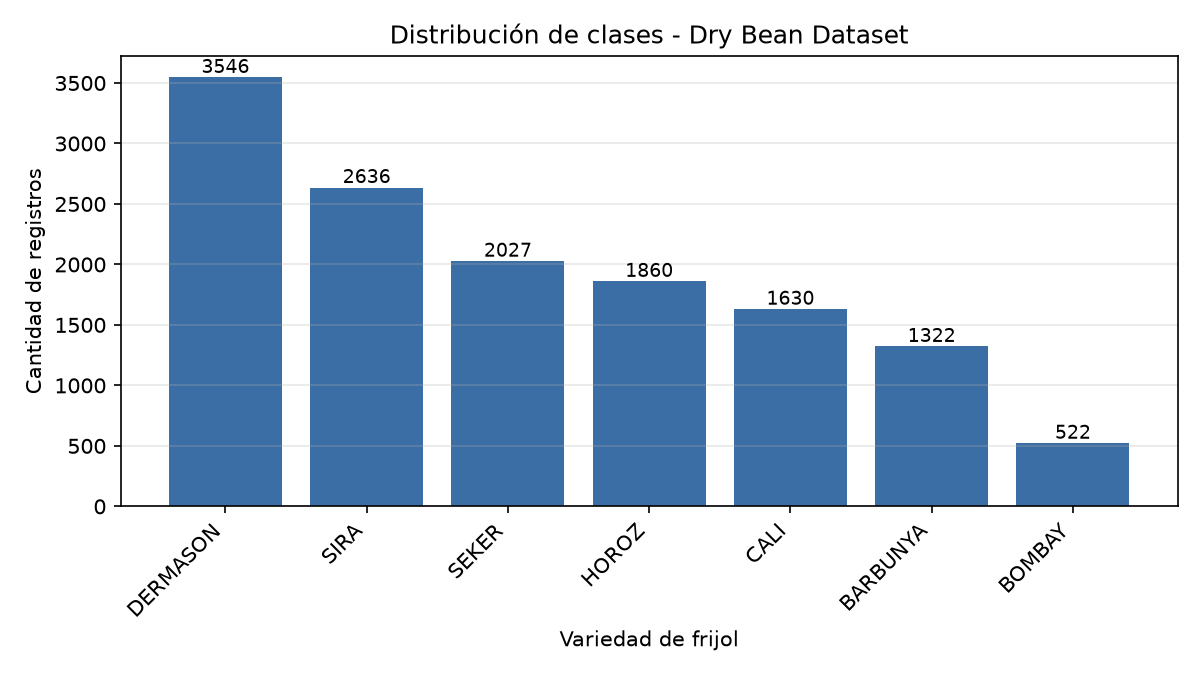


histogramas: histogramas_variables.png


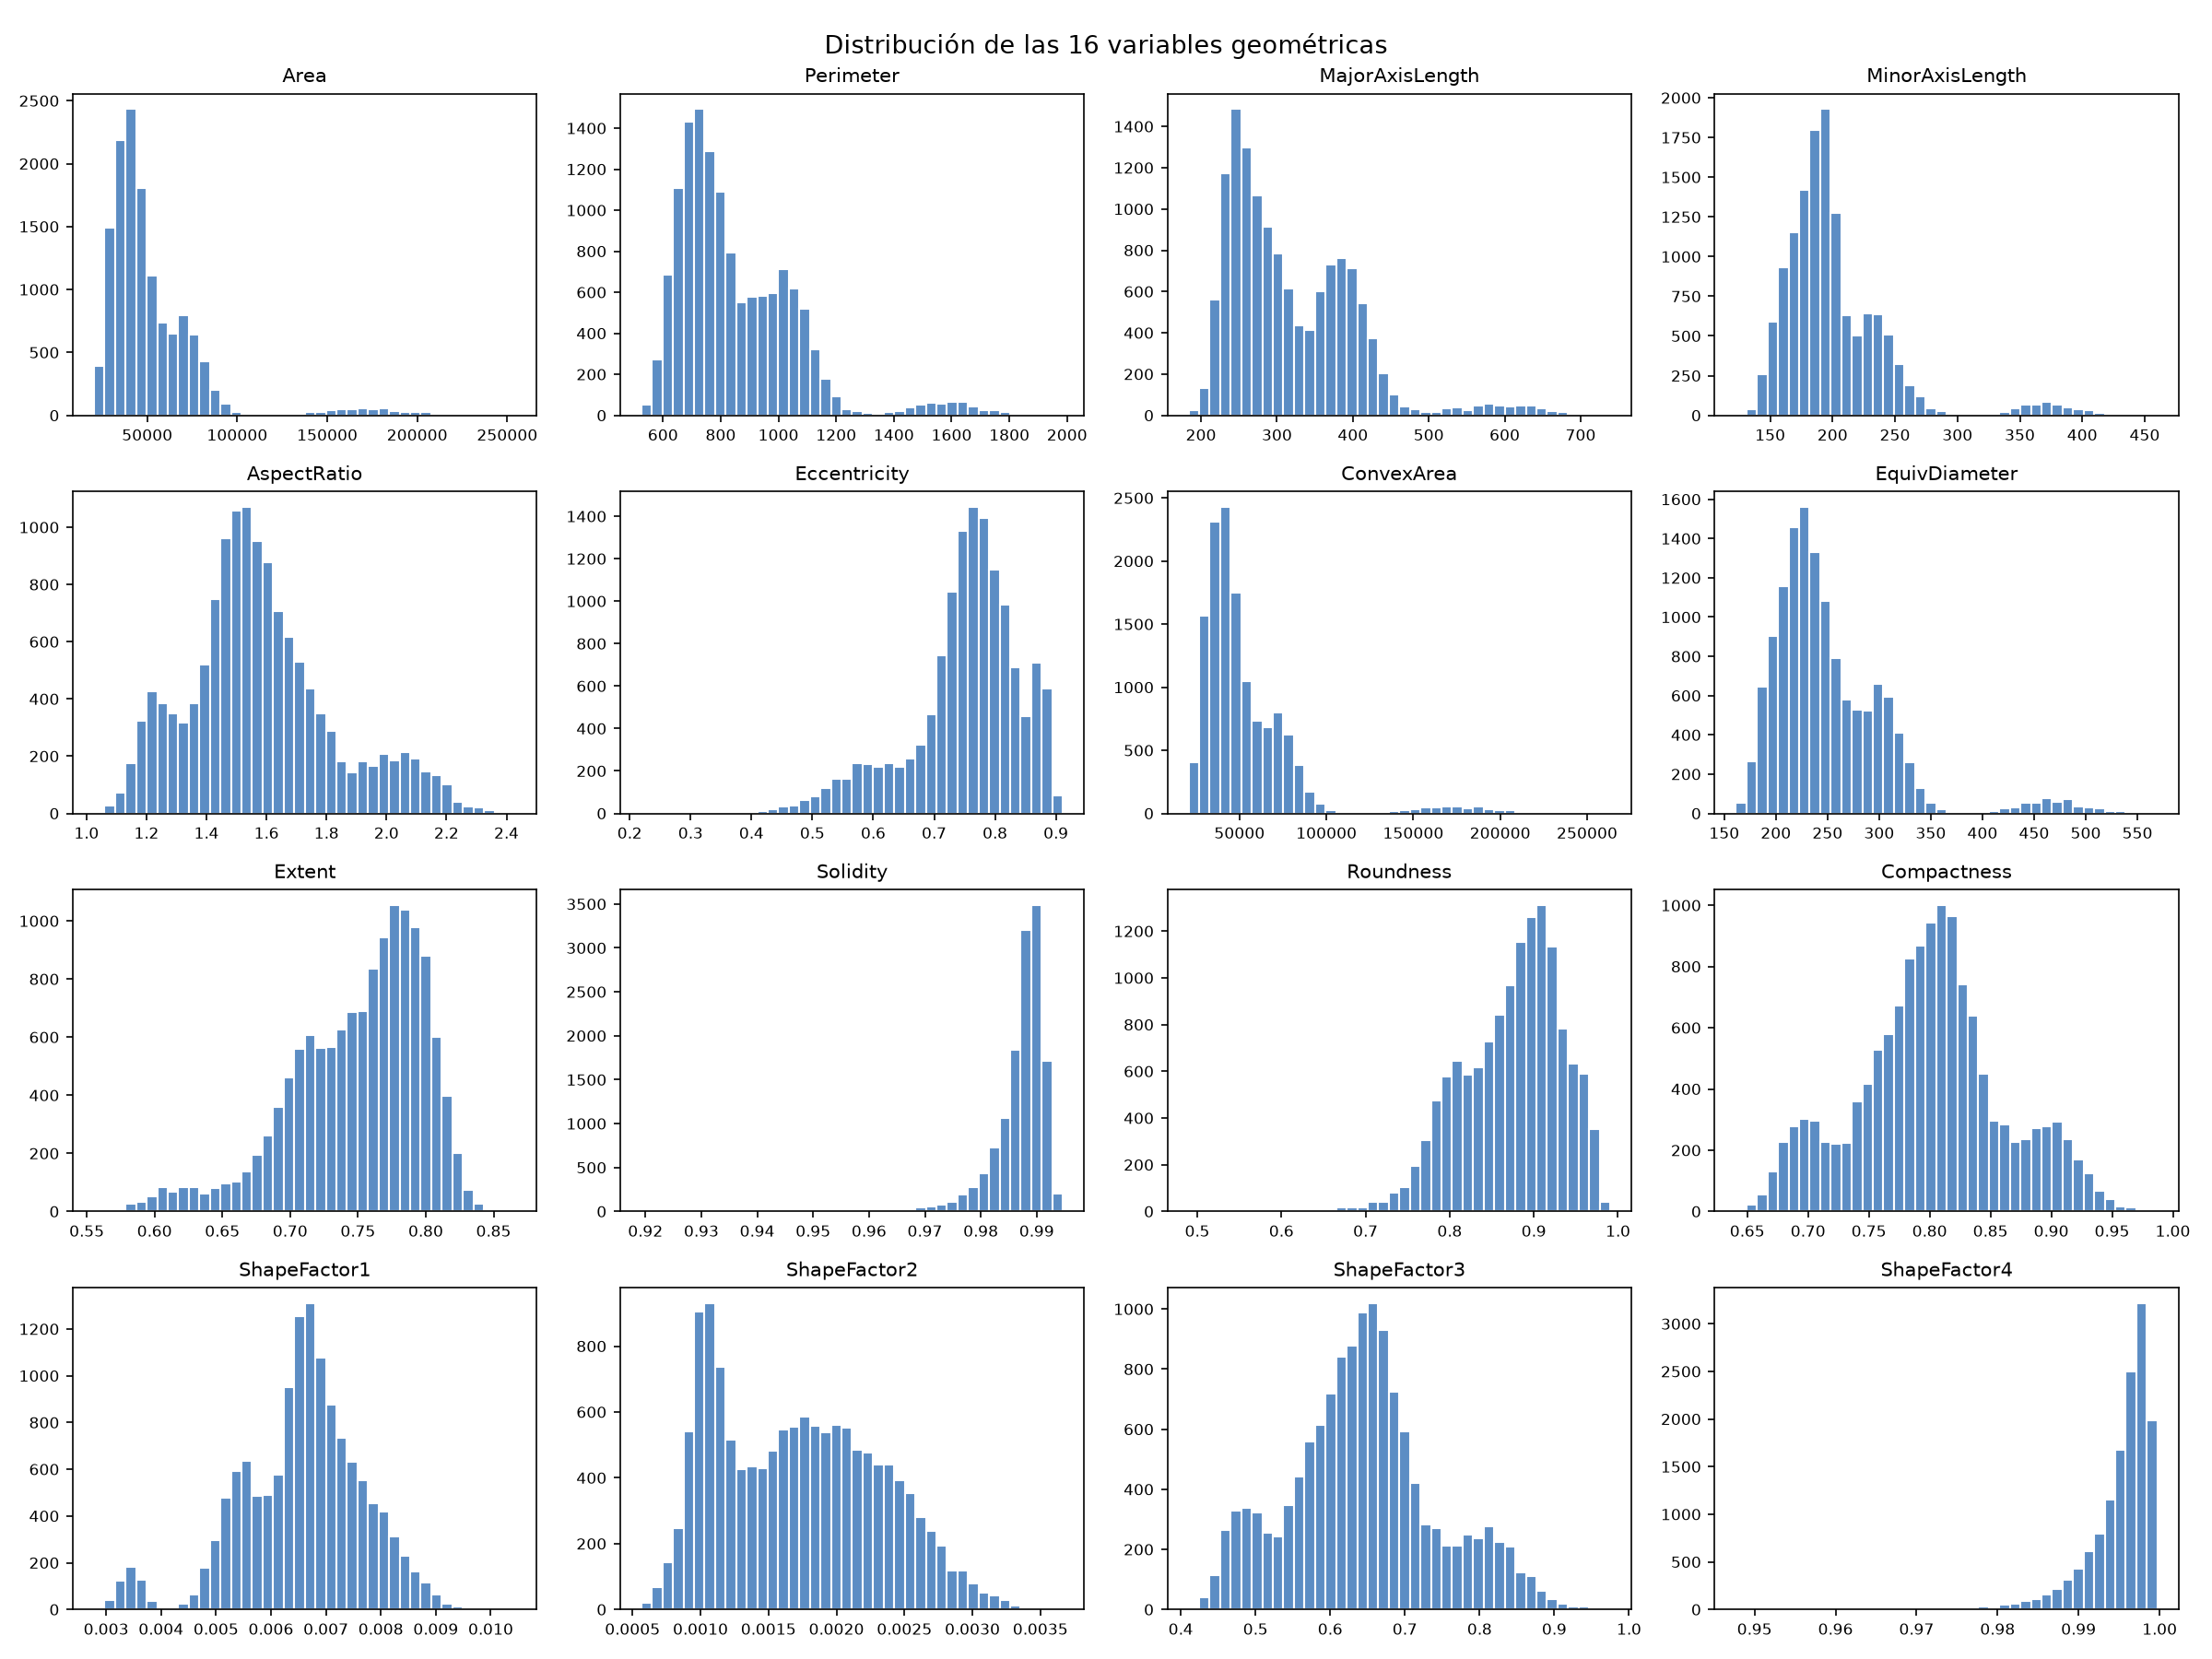


correlacion: correlacion_variables.png


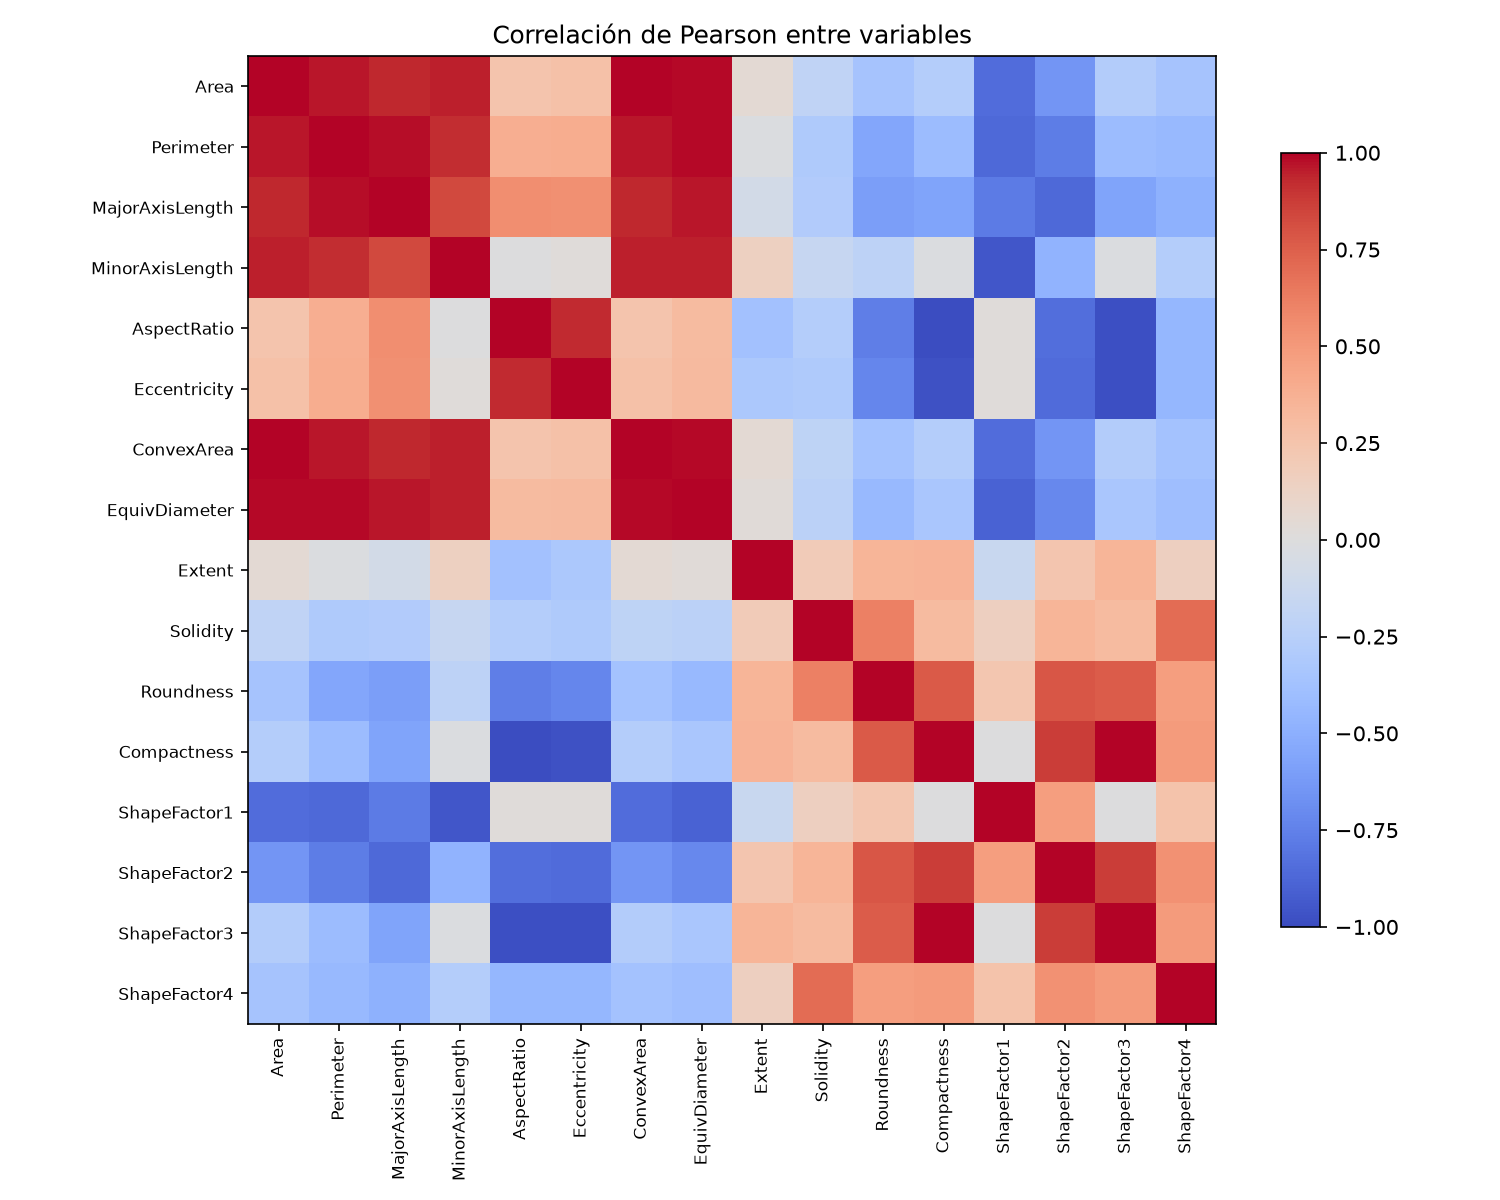


area_por_clase: area_por_clase.png


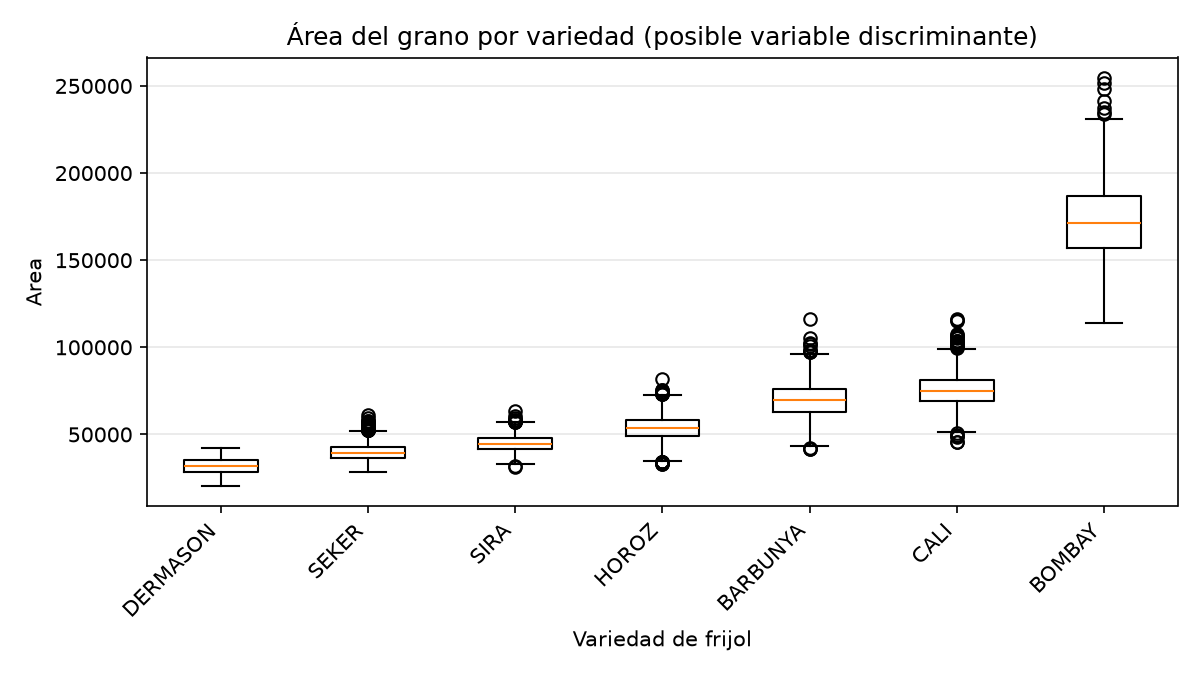

In [8]:
figures = eda.generate_figures(df)

from IPython.display import Image, display

for name, path in figures.items():
    print(f"\n{name}: {path.name}")
    display(Image(filename=str(path)))

**Pregunta del laboratorio:** ¿las clases están balanceadas? ¿cómo afecta al entrenamiento?

**Respuesta:** no. `DERMASON` (3546) tiene ~6.8 veces más registros que `BOMBAY` (522).
Sin corrección, el modelo tiende a favorecer las clases mayoritarias y el accuracy
puede verse bien aunque las clases minoritarias fallen. Por eso reportaremos
**F1 macro** y usaremos `class_weight="balanced"` en el Random Forest.

In [9]:
class_table = (
    df[config.TARGET_COLUMN]
    .value_counts()
    .rename("registros")
    .to_frame()
    .assign(porcentaje=lambda t: (t["registros"] / t["registros"].sum() * 100).round(2))
)
class_table.index.name = "Clase"
print(dataframe_to_markdown(class_table, float_format="{:.2f}"))

| Clase | registros | porcentaje |
|---|---|---|
| DERMASON | 3546 | 26.18 |
| SIRA | 2636 | 19.46 |
| SEKER | 2027 | 14.97 |
| HOROZ | 1860 | 13.73 |
| CALI | 1630 | 12.04 |
| BARBUNYA | 1322 | 9.76 |
| BOMBAY | 522 | 3.85 |


## 5. Separación X / y y train-test split

- `stratify=y` mantiene la proporción de clases en train y test.
- `random_state=42` garantiza que Rommel y Jacobo obtengan el mismo split (TDSP).
- El escalamiento se ajusta **solo con train** para evitar fuga de información.

In [10]:
X, y = prepare.split_features_target(df)
X_train, X_test, y_train, y_test = prepare.make_train_test_split(X, y)
split = prepare.describe_split(X_train, X_test, y_train, y_test)

print(f"Train: {split['train_rows']} ({split['train_share']:.1%})")
print(f"Test:  {split['test_rows']} ({split['test_share']:.1%})")
print(f"Features: {split['n_features']}")
print("Desvío máximo de proporción de clase:", round(split["max_class_share_diff"], 6))

Train: 10834 (80.0%)
Test:  2709 (20.0%)
Features: 16
Desvío máximo de proporción de clase: 0.000259


In [11]:
comparacion = pd.DataFrame(
    {"train": split["train_class_share"], "test": split["test_class_share"]}
)
comparacion.index.name = "Clase"
print(dataframe_to_markdown(comparacion, float_format="{:.4f}"))

| Clase | train | test |
|---|---|---|
| BARBUNYA | 0.0976 | 0.0978 |
| BOMBAY | 0.0386 | 0.0384 |
| CALI | 0.1204 | 0.1203 |
| DERMASON | 0.2619 | 0.2617 |
| HOROZ | 0.1373 | 0.1373 |
| SEKER | 0.1496 | 0.1499 |
| SIRA | 0.1947 | 0.1945 |


## 6. Pipeline de preprocesamiento

Se define una sola vez y se reutiliza en el Sprint 2 para el baseline y el modelo alternativo.

In [12]:
pipeline = prepare.build_preprocessing_pipeline()
X_train_scaled = pipeline.fit_transform(X_train)
X_test_scaled = pipeline.transform(X_test)

print("Pipeline:", pipeline)
print("Forma train escalado:", X_train_scaled.shape)
print("Media por variable (~0):", X_train_scaled.mean(axis=0).round(10)[:5], "...")
print("Desvío por variable (~1):", X_train_scaled.std(axis=0).round(10)[:5], "...")
print("Nulos tras escalar:", int(pd.isna(X_train_scaled).sum()))

Pipeline: Pipeline(steps=[('scaler', StandardScaler())])
Forma train escalado: (10834, 16)
Media por variable (~0): [-0.  0. -0. -0.  0.] ...
Desvío por variable (~1): [1. 1. 1. 1. 1.] ...
Nulos tras escalar: 0


## 7. Persistencia de los datos procesados

Guardamos los conjuntos procesados para reutilizarlos en el Sprint 2 sin repetir el split.

In [13]:
paths = prepare.save_processed_data(X_train, X_test, y_train, y_test)
for name, path in paths.items():
    print(f"{name}: {path}")

X_train: C:\Users\Jacobo\Documents\GestionProyectosIA\laboratorio_drybean_ml\data\processed\X_train.csv


X_test: C:\Users\Jacobo\Documents\GestionProyectosIA\laboratorio_drybean_ml\data\processed\X_test.csv
y_train: C:\Users\Jacobo\Documents\GestionProyectosIA\laboratorio_drybean_ml\data\processed\y_train.csv
y_test: C:\Users\Jacobo\Documents\GestionProyectosIA\laboratorio_drybean_ml\data\processed\y_test.csv


## 8. Conclusiones del Sprint 1

1. El dataset se obtiene de forma reproducible desde UCI y queda versionado en `data/raw/`.
2. No hay valores nulos; se eliminaron 68 filas duplicadas de forma documentada.
3. Las clases están desbalanceadas (6.79:1), lo que obliga a usar F1 macro y pesos balanceados.
4. El split estratificado deja proporciones idénticas de clase entre train y test.
5. El pipeline de escalamiento queda listo para el baseline del Sprint 2.

## 9. Siguiente paso (Sprint 2)

- **PB-03:** baseline `LogisticRegression` + `StandardScaler` (accuracy y F1 macro).
- **PB-04:** `RandomForestClassifier` con `class_weight="balanced"`.
- **PB-05:** comparación de métricas, matriz de confusión e importancia de variables.
